# Choosing one training target per identity

AggFace maps several anonymized frames of a person onto a **single clear image**, so training it needs one target image per identity. This notebook picks that frame.

Two properties decide whether a frame makes a good target:

1. **How well a recognizer identifies it.** The target is the best the reconstruction can ever be, so a mediocre target caps the whole model.
2. **Pose, consistently across identities.** The aggregator pools with a fixed learned query, so nothing tells the decoder which pose to produce. If the targets point in all directions the decoder can only learn their average, which is a blurry face.

So: of the frames a recognizer identifies better than average for that person, take the most frontal one. Neither step has a threshold to choose.

The notebook reads only `data/voxceleb2.parquet` and `data/voxceleb2_split.parquet`, so it applies to any corpus with that structure. Targets are produced for the **train and validation** identities only; test identities never appear in training.

In [7]:
import multiprocessing
import os
from concurrent.futures import ProcessPoolExecutor

import cv2
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib import pyplot as plt
from numpy.typing import NDArray
from tqdm.auto import tqdm

from meles.alignment import ARCFACE_TEMPLATE, umeyama
from meles.detection import FacialArea, default_detector
from meles.paths import repository_root
from meles.recognition import ARCFACE, FrameEmbedder

sns.set_theme(style="whitegrid")

ROOT = repository_root()
DATA = ROOT / "data"
FRAMES = DATA / "voxceleb2_frames.parquet"
EMBEDDINGS = DATA / "voxceleb2_frames.npy"
TARGETS = DATA / "voxceleb2_targets.parquet"

SEED = 0
FRAMES_PER_VIDEO = 2  # candidates drawn from each video, so every sighting contributes
CHUNK = 2000  # frames per detection task
WORKERS = max(1, (os.cpu_count() or 2) - 1)

structure = pd.read_parquet(DATA / "voxceleb2.parquet")
split = pd.read_parquet(DATA / "voxceleb2_split.parquet")
trainable = split.loc[split["split"] != "test", "identity"]

candidates = (
    structure[structure["identity"].isin(trainable)]
    .sample(frac=1, random_state=SEED)
    .groupby(["identity", "video"], sort=False)
    .head(FRAMES_PER_VIDEO)
    .sort_values(["identity", "video", "clip", "second"])
    .reset_index(drop=True)
)
print(f"{len(candidates):,} candidate frames over {candidates['identity'].nunique():,} identities")
candidates.head()

262,288 candidate frames over 5,394 identities


,identity,video,clip,second,frame,frame_suffix,path
0,id00012,21Uxsk56VDQ,00006,4,00006.0004.jpg,.jpg,voxceleb2/id00012/21Uxsk56VDQ/00006.0004.jpg
1,id00012,21Uxsk56VDQ,00007,3,00007.0003.jpg,.jpg,voxceleb2/id00012/21Uxsk56VDQ/00007.0003.jpg
2,id00012,2DLq_Kkc1r8,00017,1,00017.0001.jpg,.jpg,voxceleb2/id00012/2DLq_Kkc1r8/00017.0001.jpg
3,id00012,2DLq_Kkc1r8,00017,9,00017.0009.jpg,.jpg,voxceleb2/id00012/2DLq_Kkc1r8/00017.0009.jpg
4,id00012,73OrGYvy4ng,00019,2,00019.0002.jpg,.jpg,voxceleb2/id00012/73OrGYvy4ng/00019.0002.jpg


## Detect once, then embed

Both properties come from the same detection. The landmarks give the pose, and the aligned crop built from them gives the embedding, so the faces are located once and the result is handed to the recognizer rather than detected again.

Detection is spread over processes; the recognizer runs in one, because it batches on the accelerator. Both results are cached, since together they are the expensive part of this notebook.

In [8]:
def frontality(landmarks: NDArray[np.float32]) -> float:
    """RMS distance to the frontal template after the best similarity fit, in template pixels."""
    matrix = umeyama(landmarks, ARCFACE_TEMPLATE)
    aligned = landmarks @ matrix[:, :2].T + matrix[:, 2]
    return float(np.sqrt(((aligned - ARCFACE_TEMPLATE) ** 2).sum(axis=1).mean()))


def detect_frames(paths: list[str]) -> list[tuple[FacialArea | None, float]]:
    """The face and its pose residual for each frame."""
    found = []
    for path in paths:
        area = default_detector.detect(cv2.imread(str(DATA / path)))
        found.append((area, frontality(area.landmarks) if area else float("inf")))
    return found


if FRAMES.exists() and EMBEDDINGS.exists():
    candidates = pd.read_parquet(FRAMES)
    embeddings = np.load(EMBEDDINGS)
else:
    paths = list(candidates["path"])
    tasks = [paths[start : start + CHUNK] for start in range(0, len(paths), CHUNK)]

    context = multiprocessing.get_context("fork")
    with ProcessPoolExecutor(max_workers=WORKERS, mp_context=context) as pool:
        parts = list(tqdm(pool.map(detect_frames, tasks), total=len(tasks), desc=f"{CHUNK}-frame chunks"))

    detected = [entry for part in parts for entry in part]
    areas = [area for area, _ in detected]
    candidates["residual"] = [residual for _, residual in detected]

    embeddings = FrameEmbedder(ARCFACE).embed([str(DATA / path) for path in paths], areas=areas)

    candidates.to_parquet(FRAMES, index=False)
    np.save(EMBEDDINGS, embeddings)

# Unit vectors, so every comparison below is a plain cosine. Without normalising, the longest
# vectors would dominate and the ranking would be by embedding norm rather than by identity.
unit = embeddings / np.linalg.norm(embeddings, axis=1, keepdims=True)
print(f"{unit.shape[0]:,} embeddings of {unit.shape[1]} dimensions")

262,288 embeddings of 512 dimensions


## Does a mean embedding represent a person?

The next step scores each frame against a **pooled** embedding of an identity - the mean of that person's frames, renormalised. That takes for granted that averaging unit vectors of one person still points at that person, which nothing here has shown.

So it is checked first. Each identity is represented three ways - by one of its frames, by the mean of them, by the median - and every frame is identified against a gallery built that way. An identity's own representation always excludes the probe's video, so a frame is never matched against near duplicates of itself.

This runs on a subsample of identities, because it compares every frame against every identity. It is a relative comparison, so the smaller gallery only makes all three numbers easier together.


In [9]:
POOLING_IDENTITIES = 200

rng = np.random.default_rng(SEED)


def represent(block: NDArray[np.float32], how: str) -> NDArray[np.float32]:
    """One unit vector standing for a set of frames of the same person."""
    if how == "single frame":
        pooled = block[rng.integers(len(block))]
    elif how == "mean":
        pooled = block.mean(axis=0)
    else:
        pooled = np.median(block, axis=0)
    return pooled / np.linalg.norm(pooled)


everyone = candidates["identity"].unique()
sampled = rng.choice(everyone, size=min(POOLING_IDENTITIES, len(everyone)), replace=False)
rows = np.flatnonzero(candidates["identity"].isin(sampled).to_numpy())
sub_unit, sub = unit[rows], candidates.iloc[rows]
sub_identity, sub_video = sub["identity"].to_numpy(), sub["video"].to_numpy()
sub_names = np.array(sorted(set(sub_identity)))

print(f"{len(sub):,} frames over {len(sub_names)} identities\n")
for how in ("single frame", "mean", "median"):
    gallery = np.stack([represent(sub_unit[sub_identity == name], how) for name in sub_names])
    similarity = sub_unit @ gallery.T

    # Replace each frame's score against its own identity with one that excludes its own video.
    for column, name in enumerate(sub_names):
        mine = sub_identity == name
        for video in np.unique(sub_video[mine]):
            probe = np.flatnonzero(mine & (sub_video == video))
            rest = np.flatnonzero(mine & (sub_video != video))
            if len(rest):
                similarity[probe, column] = sub_unit[probe] @ represent(sub_unit[rest], how)

    rank_1 = (sub_names[similarity.argmax(1)] == sub_identity).mean()
    print(f"rank-1, identity represented by its {how:12s}: {rank_1:.3f}")


10,152 frames over 200 identities

rank-1, identity represented by its single frame: 0.919
rank-1, identity represented by its mean        : 0.975
rank-1, identity represented by its median      : 0.973


## How well is each frame identified?

Each frame is scored the way the experiment's classifier would score it, as a **margin**:

    margin = similarity to its own identity - similarity to the closest other identity

A high margin means the frame is unambiguously that person; a low one means it could be someone else.

The "own identity" half is computed against that identity's **other videos only**. Frames of one video are near duplicates, so comparing a frame against its own video would measure redundancy rather than identifiability - the same trap the fold split exists to avoid.

In [10]:
IMPOSTOR_BLOCK = 20_000  # frames compared against every identity at once


def group_sums(values: NDArray[np.float32], code: NDArray[np.intp]) -> tuple[NDArray[np.float32], NDArray[np.intp]]:
    """The sum and the size of each group, for group labels numbered from zero."""
    order = np.argsort(code, kind="stable")
    starts = np.flatnonzero(np.r_[True, np.diff(code[order]) != 0])
    return np.add.reduceat(values[order], starts, axis=0), np.diff(np.r_[starts, len(code)])


identity_code, identities = pd.factorize(candidates["identity"], sort=True)
video_code, _ = pd.factorize(pd.MultiIndex.from_frame(candidates[["identity", "video"]]), sort=True)

identity_sum, identity_count = group_sums(unit, identity_code)
video_sum, video_count = group_sums(unit, video_code)

# Genuine similarity: each frame against its own identity, built from that identity's other
# videos only. Frames of one video are near duplicates, so comparing a frame against its own
# video would measure redundancy rather than identifiability - the trap the fold split avoids.
rest_sum = identity_sum[identity_code] - video_sum[video_code]
rest_count = identity_count[identity_code] - video_count[video_code]
centroid = rest_sum / np.maximum(rest_count, 1)[:, None]
centroid /= np.maximum(np.linalg.norm(centroid, axis=1, keepdims=True), 1e-12)
# An identity with a single video has nothing to compare against, so it scores zero and sorts last.
genuine = np.where(rest_count > 0, (unit * centroid).sum(axis=1), 0.0).astype(np.float32)

# Impostor similarity: the best match among all the other identities. In blocks, because the
# full frames-by-identities matrix would not fit in memory.
gallery = identity_sum / identity_count[:, None]
gallery /= np.linalg.norm(gallery, axis=1, keepdims=True)

impostor = np.empty(len(candidates), dtype=np.float32)
for start in tqdm(range(0, len(candidates), IMPOSTOR_BLOCK), desc="impostor"):
    stop = min(start + IMPOSTOR_BLOCK, len(candidates))
    block = unit[start:stop] @ gallery.T
    block[np.arange(stop - start), identity_code[start:stop]] = -np.inf
    impostor[start:stop] = block.max(axis=1)

candidates["margin"] = genuine - impostor
candidates[["margin", "residual"]].describe()


impostor:   0%|          | 0/14 [00:00<?, ?it/s]

,margin,residual
count,262288.000000,262288.000000
mean,0.390630,4.273653
std,0.155335,2.208276
min,-0.920572,0.188823
25%,0.327681,2.850859
50%,0.420934,3.616297
75%,0.493633,5.026188
max,0.721451,21.254754


## How frontal is each frame?

`umeyama` fits a **similarity** transform - rotation, uniform scale, translation - from the five landmarks onto the frontal template. Such a transform can undo an in-plane tilt of the head but cannot represent a turn away from the camera, so whatever distance is left after the best possible fit is the part of the pose that could not be corrected. The score is a distance, so **lower is more frontal** and zero would be a perfectly frontal face.

That is the claim; the cell below checks it. Three crude pose measures are read straight off the landmarks - how far the nose sits off the centre line between the eyes (yaw), how far it sits below them (pitch), and the tilt of the eye line itself (roll) - and compared against the residual. If the residual measures what it should, it tracks yaw and pitch and ignores roll.


pose check:   0%|          | 0/1500 [00:00<?, ?it/s]

Spearman correlation with the pose residual
  yaw     +0.842
  pitch   +0.538
  roll    +0.188


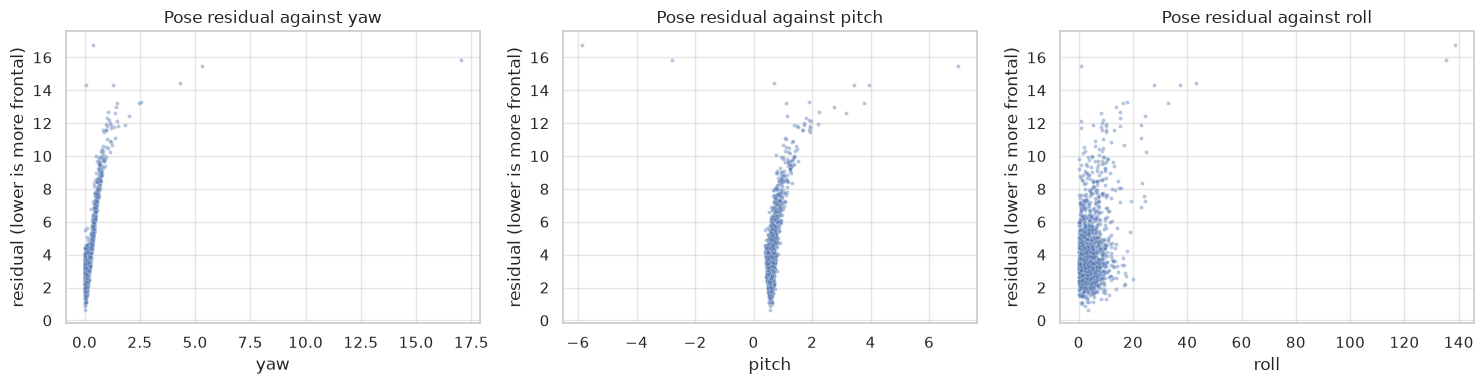

In [11]:
POSE_SAMPLE = 1500


def head_pose(landmarks: NDArray[np.float32]) -> tuple[float, float, float]:
    """Yaw, pitch and roll read off the five landmarks, in units of the distance between the eyes."""
    left_eye, right_eye = landmarks[0], landmarks[1]
    between = right_eye - left_eye
    roll = float(np.degrees(np.arctan2(between[1], between[0])))

    # Turn the head upright first, so the nose position measures a turn and not a tilt.
    angle = np.radians(-roll)
    rotation = np.array([[np.cos(angle), -np.sin(angle)], [np.sin(angle), np.cos(angle)]])
    upright = (landmarks - left_eye) @ rotation.T

    distance = float(np.linalg.norm(between))
    nose = upright[2]
    return float((nose[0] - distance / 2) / distance), float(nose[1] / distance), roll


poses = []
for path in tqdm(candidates["path"].sample(POSE_SAMPLE, random_state=SEED), desc="pose check"):
    area = default_detector.detect(cv2.imread(str(DATA / path)))
    if area is None:
        continue
    yaw, pitch, roll = head_pose(area.landmarks)
    poses.append({"residual": frontality(area.landmarks), "yaw": abs(yaw), "pitch": pitch, "roll": abs(roll)})

poses = pd.DataFrame(poses)
print("Spearman correlation with the pose residual")
for column in ("yaw", "pitch", "roll"):
    print(f"  {column:7s} {poses['residual'].corr(poses[column], method='spearman'):+.3f}")

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for axis, column in zip(axes, ("yaw", "pitch", "roll")):
    sns.scatterplot(poses, x=column, y="residual", s=8, alpha=0.4, ax=axis)
    axis.set_title(f"Pose residual against {column}")
    axis.set_ylabel("residual (lower is more frontal)")
fig.tight_layout()
plt.show()


## The pick

The two properties pull in different directions - **margin: higher is better**, **pose residual: lower is better** - and are close to independent, so both are used rather than one standing in for the other.

Keep the frames whose margin is at or above the **median for that identity**, then take the most frontal of those. Using the identity's own median rather than a fixed count or quantile keeps the rule free of any number to justify, and it adapts to people whose frames are uniformly easy or uniformly hard.


In [12]:
correlation = candidates["margin"].corr(candidates["residual"], method="spearman")
print(f"Spearman correlation between margin and pose residual: {correlation:.3f}")

median_margin = candidates.groupby("identity")["margin"].transform("median")
shortlist = candidates[candidates["margin"] >= median_margin]
targets = shortlist.loc[shortlist.groupby("identity")["residual"].idxmin()].reset_index(drop=True)

print(f"\ntargets: {len(targets):,}\n")
print(f"{'':18s} {'targets':>10s} {'candidates':>12s}")
print(f"{'margin (higher)':18s} {targets['margin'].mean():>10.3f} {candidates['margin'].mean():>12.3f}")
print(f"{'residual (lower)':18s} {targets['residual'].mean():>10.3f} {candidates['residual'].mean():>12.3f}")
print(f"{'residual spread':18s} {targets['residual'].std():>10.3f} {candidates['residual'].std():>12.3f}")
targets.head()


Spearman correlation between margin and pose residual: -0.079

targets: 5,394

                      targets   candidates
margin (higher)         0.459        0.391
residual (lower)        1.974        4.274
residual spread         0.575        2.208


,identity,video,clip,second,frame,frame_suffix,path,residual,margin
0,id00012,f0Zj2NjXeyE,00139,2,00139.0002.jpg,.jpg,voxceleb2/id00012/f0Zj2NjXeyE/00139.0002.jpg,2.000799,0.509191
1,id00016,PAxhdh3dW9I,00076,4,00076.0004.jpg,.jpg,voxceleb2/id00016/PAxhdh3dW9I/00076.0004.jpg,1.746421,0.467812
2,id00018,jIHLnVT1Im4,00133,4,00133.0004.jpg,.jpg,voxceleb2/id00018/jIHLnVT1Im4/00133.0004.jpg,2.097800,0.483411
3,id00019,Eh93MxnkH9c,00021,0,00021.0000.jpg,.jpg,voxceleb2/id00019/Eh93MxnkH9c/00021.0000.jpg,2.251699,0.548091
4,id00020,fj7dYxm1p0o,00292,0,00292.0000.jpg,.jpg,voxceleb2/id00020/fj7dYxm1p0o/00292.0000.jpg,2.328650,0.506310


Both numbers should have moved the right way: a higher margin than the candidate average means the targets are easier to identify, and a smaller residual spread means they share a pose.

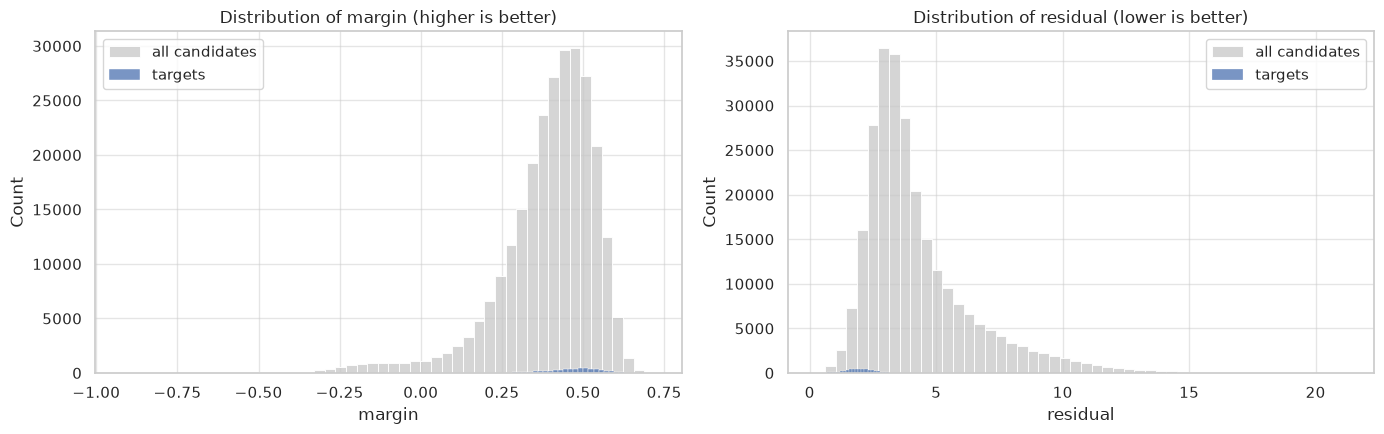

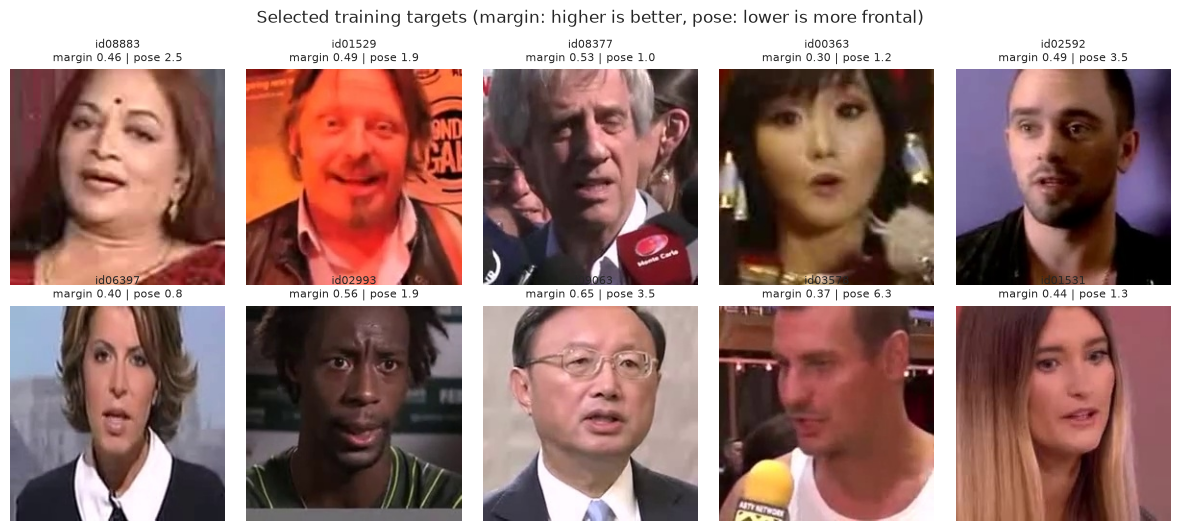

In [13]:
SHOWN = 10

fig, (ax_1, ax_2) = plt.subplots(1, 2, figsize=(14, 4.5))
for axis, column, direction in ((ax_1, "margin", "higher is better"), (ax_2, "residual", "lower is better")):
    sns.histplot(candidates[column], bins=50, color="#C7C7C7", label="all candidates", ax=axis)
    sns.histplot(targets[column], bins=50, color="#4C72B0", label="targets", ax=axis)
    axis.set_title(f"Distribution of {column} ({direction})")
    axis.set_xlabel(column)
    axis.legend()
fig.tight_layout()
plt.show()

shown = targets.sample(n=min(SHOWN, len(targets)), random_state=1)
fig, axes = plt.subplots(2, 5, figsize=(12, 5.4))
for axis, (_, target) in zip(axes.flat, shown.iterrows()):
    axis.imshow(cv2.cvtColor(cv2.imread(str(DATA / target["path"])), cv2.COLOR_BGR2RGB))
    axis.set_title(f"{target['identity']}\nmargin {target['margin']:.2f} | pose {target['residual']:.1f}", fontsize=8)
    axis.set_axis_off()
fig.suptitle("Selected training targets (margin: higher is better, pose: lower is more frontal)", fontsize=12)
fig.tight_layout()
plt.show()


## Save

One row per identity, pointing at the frame to use as that identity's target.

In [14]:
targets.to_parquet(TARGETS, index=False)
print(f"wrote {TARGETS.name}: {len(targets):,} targets")

missing = set(trainable) - set(targets["identity"])
assert not missing, f"{len(missing)} identities have no target"
assert targets["identity"].is_unique, "an identity must have exactly one target"

wrote voxceleb2_targets.parquet: 5,394 targets
